In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np  # linear algebra
import pandas as pd  # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os

for dirname, _, filenames in os.walk("/kaggle/input"):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All"
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub

# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/avcuongy/bkai-igh-neopolyp-small-sample/data/gt/26f9a7021bab9fc7330398846f67b5df.jpeg
/kaggle/input/datasets/avcuongy/bkai-igh-neopolyp-small-sample/data/gt/99fdc98376290081835cf877e004e8bf.jpeg
/kaggle/input/datasets/avcuongy/bkai-igh-neopolyp-small-sample/data/gt/c7abacdbd7e6afd56ea7bc4ba26c86b3.jpeg
/kaggle/input/datasets/avcuongy/bkai-igh-neopolyp-small-sample/data/gt/bc5d92b9076135d76d0bbd4ce2a1405f.jpeg
/kaggle/input/datasets/avcuongy/bkai-igh-neopolyp-small-sample/data/gt/f95b204727fdcfa030228a69b99df088.jpeg
/kaggle/input/datasets/avcuongy/bkai-igh-neopolyp-small-sample/data/gt/6dc55c83a46ce2be9800e6c6f4f21968.jpeg
/kaggle/input/datasets/avcuongy/bkai-igh-neopolyp-small-sample/data/gt/ad4f13ccf1f4b331a412fc44655fb51f.jpeg
/kaggle/input/datasets/avcuongy/bkai-igh-neopolyp-small-sample/data/gt/8ee924dbd70f618d52893a23c466c169.jpeg
/kaggle/input/datasets/avcuongy/bkai-igh-neopolyp-small-sample/data/gt/eb91e2da9e6afaef7fdb2d45b21960c9.jpeg
/kaggle/input/datas

# Lib


In [2]:
import warnings

warnings.filterwarnings("ignore")

In [3]:
import os
import copy
import random
from pathlib import Path
from datetime import datetime

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import albumentations as A
from albumentations.pytorch import ToTensorV2

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

from torchvision.models import resnet50, ResNet50_Weights, resnet34, ResNet34_Weights

from scipy.ndimage import binary_erosion, distance_transform_edt

import kagglehub
from logging import config

# Set Seed


In [4]:
SEED = 42


def set_seed(seed=SEED):
    os.environ["PYTHONHASHSEED"] = str(seed)

    random.seed(seed)
    np.random.seed(seed)

    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

    try:
        torch.use_deterministic_algorithms(True, warn_only=True)
    except Exception:
        pass


set_seed(SEED)
print(f"Global seed: {SEED}")

Global seed: 42


# Data Augmentation


In [ ]:
def build_train_transform(height=256, width=256):
    """Tuned train transform: Giữ nguyên biến đổi hình dáng, nhưng GIẢM biến đổi màu/sáng để cứu Class 1"""
    return A.Compose(
        [
            A.Resize(height=height, width=width),
            A.HorizontalFlip(p=0.5),
            A.VerticalFlip(p=0.5),
            A.RandomRotate90(p=0.5),
            A.ShiftScaleRotate(
                shift_limit=0.0625,
                scale_limit=0.15,
                rotate_limit=45,
                border_mode=cv2.BORDER_CONSTANT,
                p=0.5,
            ),
            A.OneOf(
                [
                    A.ElasticTransform(
                        alpha=120, sigma=120 * 0.05, alpha_affine=120 * 0.03, p=0.5
                    ),
                    A.GridDistortion(p=0.5),
                    A.OpticalDistortion(distort_limit=1, shift_limit=0.5, p=0.5),
                ],
                p=0.4,
            ),
            A.OneOf(
                [
                    A.RandomBrightnessContrast(
                        brightness_limit=0.1, contrast_limit=0.1, p=0.5
                    ),
                    A.HueSaturationValue(
                        hue_shift_limit=10,
                        sat_shift_limit=15,
                        val_shift_limit=10,
                        p=0.5,
                    ),
                ],
                p=0.3,
            ),
            A.OneOf(
                [
                    A.GaussNoise(var_limit=(10.0, 30.0), p=0.5),
                    A.GaussianBlur(blur_limit=(3, 5), p=0.5),
                ],
                p=0.2,
            ),
            A.Normalize(
                mean=(0.485, 0.456, 0.406),
                std=(0.229, 0.224, 0.225),
            ),
            ToTensorV2(),
        ]
    )


def build_eval_transform(height=256, width=256):
    """
    Deterministic validation/test transform.
    """
    return A.Compose(
        [
            A.Resize(height=height, width=width),
            A.Normalize(
                mean=(0.485, 0.456, 0.406),
                std=(0.229, 0.224, 0.225),
            ),
            ToTensorV2(),
        ]
    )

# Data Preparation


In [6]:
CLASS_NAMES = {
    0: "background",
    1: "non-neoplastic",
    2: "neoplastic",
}

CLASS_COLORS = {
    0: (0, 0, 0),
    1: (0, 255, 0),
    2: (255, 0, 0),
}


def decode_ground_truth(mask_rgb):
    """
    To RGB mask -> class-index mask 0/1/2.

    Class mapping:
        0 = background      -> black
        1 = non-neoplastic  -> green
        2 = neoplastic      -> red

    Using nearest-color matching to handle or correct any color variations in the mask image.
    This function will convert an RGB mask into a 2D array where each pixel's value corresponds to its class ID (0, 1, or 2).
    """
    mask = np.asarray(mask_rgb)

    if mask.ndim == 2:
        unique_values = np.unique(mask)

        if np.isin(unique_values, [0, 1, 2]).all():
            return mask.astype(np.uint8)

        raise ValueError(
            "Grayscale mask must contain only class IDs 0, 1, 2. "
            f"Found: {unique_values[:20]}"
        )

    if mask.ndim != 3 or mask.shape[-1] != 3:
        raise ValueError(f"Expected HxWx3 RGB mask, got shape={mask.shape}")

    colors = np.array(
        [
            [0, 0, 0],  # background
            [0, 255, 0],  # non-neoplastic
            [255, 0, 0],  # neoplastic
        ],
        dtype=np.float32,
    )

    pixels = mask.astype(np.float32)

    # Shape:
    # pixels -> [H, W, 1, 3]
    # colors -> [1, 1, 3, 3]
    # result -> [H, W, 3]
    diff = pixels[:, :, None, :] - colors[None, None, :, :]

    distances = np.sum(
        diff**2,
        axis=-1,
    )

    class_mask = np.argmin(
        distances,
        axis=-1,
    )

    return class_mask.astype(np.uint8)


def _pick_column(
    df,
    explicit_column=None,
    candidates=None,
    required=True,
):
    if explicit_column is not None:
        if explicit_column not in df.columns:
            raise KeyError(
                f"Column '{explicit_column}' not found. "
                f"Available: {df.columns.tolist()}"
            )

        return explicit_column

    candidates = candidates or []

    normalized = {str(col).strip().lower(): col for col in df.columns}

    for candidate in candidates:
        if candidate.lower() in normalized:
            return normalized[candidate.lower()]

    if len(df.columns) == 1:
        return df.columns[0]

    if required:
        raise KeyError(
            "Cannot infer CSV column automatically. "
            f"Available columns: {df.columns.tolist()}"
        )

    return None


class PolypSegmentationDataset(Dataset):
    IMAGE_COLUMN_CANDIDATES = [
        "image",
        "image_name",
        "image_path",
        "filename",
        "file_name",
        "file",
        "id",
    ]

    MASK_COLUMN_CANDIDATES = [
        "mask",
        "mask_name",
        "mask_path",
        "label",
        "label_path",
        "gt",
        "gt_path",
    ]

    def __init__(
        self,
        dataframe,
        image_dir,
        mask_dir=None,
        transform=None,
        image_col=None,
        mask_col=None,
        has_mask=True,
    ):
        self.df = dataframe.reset_index(drop=True).copy()

        self.image_dir = Path(image_dir)

        self.mask_dir = Path(mask_dir) if mask_dir is not None else None

        self.transform = transform
        self.has_mask = has_mask

        self.image_col = _pick_column(
            self.df,
            explicit_column=image_col,
            candidates=self.IMAGE_COLUMN_CANDIDATES,
            required=True,
        )

        if self.has_mask:
            if self.mask_dir is None:
                raise ValueError("mask_dir is required when has_mask=True.")

            self.mask_col = _pick_column(
                self.df,
                explicit_column=mask_col,
                candidates=self.MASK_COLUMN_CANDIDATES,
                required=False,
            )

        else:
            self.mask_col = None

    @staticmethod
    def _resolve_path(root_dir, value):
        candidate = Path(str(value))

        if candidate.is_absolute():
            return candidate

        return Path(root_dir) / str(value)

    def __len__(self):
        return len(self.df)

    def get_image_path(self, index):
        value = self.df.iloc[index][self.image_col]

        return self._resolve_path(
            self.image_dir,
            value,
        )

    def get_mask_path(self, index):
        if not self.has_mask:
            return None

        row = self.df.iloc[index]

        if self.mask_col is not None:
            mask_value = row[self.mask_col]
        else:
            mask_value = row[self.image_col]

        return self._resolve_path(
            self.mask_dir,
            mask_value,
        )

    def __getitem__(self, index):
        image_path = self.get_image_path(index)

        image_bgr = cv2.imread(
            str(image_path),
            cv2.IMREAD_COLOR,
        )

        if image_bgr is None:
            raise FileNotFoundError(f"Cannot read image: {image_path}")

        image = cv2.cvtColor(
            image_bgr,
            cv2.COLOR_BGR2RGB,
        )

        if not self.has_mask:
            if self.transform is not None:
                transformed = self.transform(image=image)

                image = transformed["image"]

            return {
                "image": image,
                "image_path": str(image_path),
                "image_name": image_path.name,
            }

        mask_path = self.get_mask_path(index)

        mask_raw = cv2.imread(
            str(mask_path),
            cv2.IMREAD_UNCHANGED,
        )

        if mask_raw is None:
            raise FileNotFoundError(f"Cannot read mask: {mask_path}")

        if mask_raw.ndim == 3:
            mask_raw = cv2.cvtColor(
                mask_raw,
                cv2.COLOR_BGR2RGB,
            )

        # Nearest-color RGB -> class ID.
        mask = decode_ground_truth(mask_raw)

        if self.transform is not None:
            transformed = self.transform(
                image=image,
                mask=mask,
            )

            image = transformed["image"]
            mask = transformed["mask"]

        if not torch.is_tensor(mask):
            mask = torch.from_numpy(mask)

        return {
            "image": image,
            "mask": mask.long(),
            "image_path": str(image_path),
            "mask_path": str(mask_path),
            "image_name": image_path.name,
        }

# Architecture


## Unet


In [7]:
class ResNetEncoder(nn.Module):
    """
    ResNet encoder backbone.

    Supports:
        resnet34, resnet50

    Returns:
        [x0, x1, x2, x3, x4]
    """

    def __init__(
        self,
        backbone="resnet34",
        pretrained=True,
    ):
        super().__init__()

        backbone = backbone.lower()

        if backbone == "resnet34":
            weights = ResNet34_Weights.DEFAULT if pretrained else None
            model = resnet34(weights=weights)
            self.out_channels = [64, 64, 128, 256, 512]

        elif backbone == "resnet50":
            weights = ResNet50_Weights.DEFAULT if pretrained else None
            model = resnet50(weights=weights)
            self.out_channels = [64, 256, 512, 1024, 2048]

        else:
            raise ValueError(
                f"Unsupported backbone: {backbone}. "
                "Supported: resnet18, resnet34, "
                "resnet50, resnet101"
            )

        self.conv1 = model.conv1
        self.bn1 = model.bn1
        self.relu = model.relu
        self.maxpool = model.maxpool

        self.layer1 = model.layer1
        self.layer2 = model.layer2
        self.layer3 = model.layer3
        self.layer4 = model.layer4

    def forward(self, x):
        x0 = self.relu(self.bn1(self.conv1(x)))  # H/2

        x = self.maxpool(x0)  # H/4
        x1 = self.layer1(x)  # H/4
        x2 = self.layer2(x1)  # H/8
        x3 = self.layer3(x2)  # H/16
        x4 = self.layer4(x3)  # H/32

        return [x0, x1, x2, x3, x4]

    def freeze(self):
        for parameter in self.parameters():
            parameter.requires_grad = False

    def unfreeze(self):
        for parameter in self.parameters():
            parameter.requires_grad = True

In [8]:
class DoubleConv(nn.Module):
    """
    (Conv2d -> BatchNorm -> ReLU) * 2
    """

    def __init__(
        self,
        in_channels,
        out_channels,
    ):
        super().__init__()

        self.double_conv = nn.Sequential(
            nn.Conv2d(
                in_channels,
                out_channels,
                kernel_size=3,
                padding=1,
                bias=False,
            ),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(
                out_channels,
                out_channels,
                kernel_size=3,
                padding=1,
                bias=False,
            ),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.double_conv(x)


class Up(nn.Module):
    """
    Upsample decoder feature, concat encoder skip, before DoubleConv.
    """

    def __init__(
        self,
        decoder_channels,
        skip_channels,
        out_channels,
        bilinear=False,
    ):
        super().__init__()

        if bilinear:
            self.up = nn.Sequential(
                nn.Upsample(
                    scale_factor=2,
                    mode="bilinear",
                    align_corners=True,
                ),
                nn.Conv2d(
                    decoder_channels,
                    out_channels,
                    kernel_size=1,
                ),
            )
        else:
            self.up = nn.ConvTranspose2d(
                decoder_channels,
                out_channels,
                kernel_size=2,
                stride=2,
            )

        self.conv = DoubleConv(
            out_channels + skip_channels,
            out_channels,
        )

    def forward(self, x, skip):
        x = self.up(x)

        diff_y = skip.size(2) - x.size(2)
        diff_x = skip.size(3) - x.size(3)

        if diff_x != 0 or diff_y != 0:
            x = F.pad(
                x,
                [
                    diff_x // 2,
                    diff_x - diff_x // 2,
                    diff_y // 2,
                    diff_y - diff_y // 2,
                ],
            )

        x = torch.cat([skip, x], dim=1)

        return self.conv(x)


class OutConv(nn.Module):
    def __init__(
        self,
        in_channels,
        n_classes,
    ):
        super().__init__()

        self.conv = nn.Conv2d(
            in_channels,
            n_classes,
            kernel_size=1,
        )

    def forward(self, x):
        return self.conv(x)


class UNet(nn.Module):
    """
    U-Net with ResNet encoder backbone.

    Output:
        logits: (B, n_classes, H, W)

    return_features=True:
        return encoder/bottleneck/decoder features.
    """

    def __init__(
        self,
        backbone="resnet34",
        n_classes=3,
        pretrained=True,
        bilinear=False,
    ):
        super().__init__()

        self.backbone_name = backbone
        self.n_classes = n_classes
        self.pretrained = pretrained
        self.bilinear = bilinear

        self.encoder = ResNetEncoder(
            backbone=backbone,
            pretrained=pretrained,
        )

        c0, c1, c2, c3, c4 = self.encoder.out_channels

        self.up4 = Up(
            decoder_channels=c4,
            skip_channels=c3,
            out_channels=256,
            bilinear=bilinear,
        )

        self.up3 = Up(
            decoder_channels=256,
            skip_channels=c2,
            out_channels=128,
            bilinear=bilinear,
        )

        self.up2 = Up(
            decoder_channels=128,
            skip_channels=c1,
            out_channels=64,
            bilinear=bilinear,
        )

        self.up1 = Up(
            decoder_channels=64,
            skip_channels=c0,
            out_channels=64,
            bilinear=bilinear,
        )

        if bilinear:
            self.final_up = nn.Sequential(
                nn.Upsample(
                    scale_factor=2,
                    mode="bilinear",
                    align_corners=True,
                ),
                nn.Conv2d(
                    64,
                    32,
                    kernel_size=1,
                ),
                nn.BatchNorm2d(32),
                nn.ReLU(inplace=True),
            )
        else:
            self.final_up = nn.Sequential(
                nn.ConvTranspose2d(
                    64,
                    32,
                    kernel_size=2,
                    stride=2,
                ),
                nn.BatchNorm2d(32),
                nn.ReLU(inplace=True),
            )

        self.outc = OutConv(
            32,
            n_classes,
        )

    def forward(
        self,
        x,
        return_features=False,
    ):
        input_size = x.shape[-2:]

        features = self.encoder(x)
        x0, x1, x2, x3, x4 = features

        x = self.up4(x4, x3)
        x = self.up3(x, x2)
        x = self.up2(x, x1)
        x = self.up1(x, x0)

        decoder_feature = self.final_up(x)

        logits = self.outc(decoder_feature)

        if logits.shape[-2:] != input_size:
            logits = F.interpolate(
                logits,
                size=input_size,
                mode="bilinear",
                align_corners=False,
            )

        if return_features:
            return logits, {
                "encoder_0": x0,
                "encoder_1": x1,
                "encoder_2": x2,
                "encoder_3": x3,
                "bottleneck": x4,
                "decoder": decoder_feature,
            }

        return logits

    def freeze_encoder(self):
        self.encoder.freeze()

    def unfreeze_encoder(self):
        self.encoder.unfreeze()

# Func


## Metrics


In [9]:
def multiclass_dice_score(
    logits,
    targets,
    num_classes=3,
    include_background=False,
    eps=1e-7,
):
    """
    Mean per-class Dice over the batch.

    For each class, samples where both GT and prediction are empty are
    excluded from that class's mean. This prevents rare classes from
    receiving artificial Dice=1 scores simply because the class is absent.
    """
    preds = torch.argmax(logits, dim=1)
    start_class = 0 if include_background else 1
    scores = []

    for class_id in range(start_class, num_classes):
        pred_c = preds == class_id
        target_c = targets == class_id

        intersection = (pred_c & target_c).sum(dim=(1, 2)).float()

        denominator = pred_c.sum(dim=(1, 2)).float() + target_c.sum(dim=(1, 2)).float()

        valid = denominator > 0

        if valid.any():
            score = (2.0 * intersection[valid] + eps) / (denominator[valid] + eps)

            scores.append(score.mean())

    if not scores:
        return torch.tensor(
            0.0,
            device=logits.device,
        )

    return torch.stack(scores).mean()


def hd95_binary(pred_mask, true_mask):
    """
    Compute symmetric HD95 when both GT and prediction contain the class.

    If either side is empty, HD95 is undefined because there are not two
    surfaces to compare, so NaN is returned. Dataset-level evaluation keeps
    using np.nanmean, meaning only valid surface-distance cases contribute.
    """
    pred = np.asarray(pred_mask).astype(bool)
    true = np.asarray(true_mask).astype(bool)

    if not pred.any() or not true.any():
        return np.nan

    pred_surface = pred ^ binary_erosion(pred)
    true_surface = true ^ binary_erosion(true)

    if not pred_surface.any():
        pred_surface = pred

    if not true_surface.any():
        true_surface = true

    dist_to_true = distance_transform_edt(~true_surface)
    dist_to_pred = distance_transform_edt(~pred_surface)

    d1 = dist_to_true[pred_surface]
    d2 = dist_to_pred[true_surface]
    distances = np.concatenate([d1, d2])

    return float(np.percentile(distances, 95))


def _safe_divide(numerator, denominator):
    if denominator == 0:
        return np.nan
    return float(numerator / denominator)

## Loss


In [ ]:
class GeneralizedDiceLoss(nn.Module):
    """Generalized Dice Loss (GDL): Automatically balances class weights based on the inverse square of the true area."""

    def __init__(self, num_classes=3, smooth=1e-6, ignore_index=None):
        super().__init__()
        self.num_classes = num_classes
        self.smooth = smooth
        self.ignore_index = ignore_index

    def forward(self, logits, targets):
        probabilities = torch.softmax(logits, dim=1)

        if self.ignore_index is not None:
            valid_mask = targets != self.ignore_index
            safe_targets = torch.where(valid_mask, targets, torch.zeros_like(targets))
        else:
            valid_mask = torch.ones_like(targets, dtype=torch.bool)
            safe_targets = targets

        targets_one_hot = F.one_hot(safe_targets.long(), num_classes=self.num_classes)
        targets_one_hot = targets_one_hot.permute(0, 3, 1, 2).float()
        valid_mask = valid_mask.unsqueeze(1).float()
        probabilities = probabilities * valid_mask
        targets_one_hot = targets_one_hot * valid_mask

        dims = (0, 2, 3)
        targets_sum = torch.sum(targets_one_hot, dim=dims)

        present = targets_sum > 0
        safe_targets_sum = torch.where(
            present,
            targets_sum,
            torch.ones_like(targets_sum),
        )
        weights = present.to(probabilities.dtype) / (
            safe_targets_sum + self.smooth
        ).pow(2)
        weights = weights / weights.sum().clamp_min(self.smooth)

        intersection = torch.sum(probabilities * targets_one_hot, dim=dims)
        pred_sum = torch.sum(probabilities, dim=dims)

        weighted_intersection = torch.sum(weights * intersection)
        weighted_denominator = torch.sum(weights * (pred_sum + targets_sum))

        gdl = (2.0 * weighted_intersection + self.smooth) / (
            weighted_denominator + self.smooth
        )
        return 1.0 - gdl


class WeightedCE_GDL_Loss(nn.Module):
    def __init__(
        self,
        class_weights=None,
        num_classes=3,
        ce_loss_weight=1.0,
        gdl_loss_weight=1.0,
        smooth=1e-6,
        ignore_index=-100,
    ):
        super().__init__()
        self.ce_loss_weight = float(ce_loss_weight)
        self.gdl_loss_weight = float(gdl_loss_weight)

        ce_weights = (
            torch.tensor(class_weights, dtype=torch.float32)
            if class_weights is not None
            else None
        )

        self.register_buffer("ce_weights", ce_weights, persistent=True)

        self.cross_entropy = nn.CrossEntropyLoss(
            weight=self.ce_weights, ignore_index=ignore_index
        )
        self.gdl = GeneralizedDiceLoss(
            num_classes=num_classes, smooth=smooth, ignore_index=ignore_index
        )

    def get_extra_state(self):
        return {
            "ce_loss_weight": self.ce_loss_weight,
            "gdl_loss_weight": self.gdl_loss_weight,
            "num_classes": self.gdl.num_classes,
            "smooth": self.gdl.smooth,
            "ignore_index": self.gdl.ignore_index,
        }

    def set_extra_state(self, state):
        if not state:
            return

        self.ce_loss_weight = float(state["ce_loss_weight"])
        self.gdl_loss_weight = float(state["gdl_loss_weight"])
        self.gdl.num_classes = int(state["num_classes"])
        self.gdl.smooth = float(state["smooth"])
        self.gdl.ignore_index = state["ignore_index"]
        self.cross_entropy.ignore_index = state["ignore_index"]

    def forward(self, logits, targets):
        ce_loss = self.cross_entropy(logits, targets)
        gdl_loss = self.gdl(logits, targets)
        return self.ce_loss_weight * ce_loss + self.gdl_loss_weight * gdl_loss

## Training Utils


In [11]:
def train_one_epoch(
    model,
    loader,
    criterion,
    optimizer,
    device,
    num_classes=3,
):
    model.train()

    running_loss = 0.0
    running_dice = 0.0
    total_samples = 0

    for batch in loader:
        images = batch["image"].to(
            device,
            non_blocking=True,
        )
        masks = (
            batch["mask"]
            .to(
                device,
                non_blocking=True,
            )
            .long()
        )

        optimizer.zero_grad(set_to_none=True)

        logits = model(images)
        loss = criterion(logits, masks)

        loss.backward()
        optimizer.step()

        batch_size = images.size(0)

        with torch.no_grad():
            dice = multiclass_dice_score(
                logits,
                masks,
                num_classes=num_classes,
                include_background=False,
            )

        running_loss += loss.item() * batch_size
        running_dice += dice.item() * batch_size
        total_samples += batch_size

    return (
        running_loss / max(total_samples, 1),
        running_dice / max(total_samples, 1),
    )


@torch.no_grad()
def validate_one_epoch(
    model,
    loader,
    criterion,
    device,
    num_classes=3,
):
    model.eval()

    running_loss = 0.0
    running_dice = 0.0
    total_samples = 0

    for batch in loader:
        images = batch["image"].to(
            device,
            non_blocking=True,
        )
        masks = (
            batch["mask"]
            .to(
                device,
                non_blocking=True,
            )
            .long()
        )

        logits = model(images)
        loss = criterion(logits, masks)

        batch_size = images.size(0)

        dice = multiclass_dice_score(
            logits,
            masks,
            num_classes=num_classes,
            include_background=False,
        )

        running_loss += loss.item() * batch_size
        running_dice += dice.item() * batch_size
        total_samples += batch_size

    return (
        running_loss / max(total_samples, 1),
        running_dice / max(total_samples, 1),
    )

## Checkpoint Utils


In [12]:
def clone_state_dict_to_cpu(model):
    return {
        key: value.detach().cpu().clone() for key, value in model.state_dict().items()
    }


def empty_history():
    return {
        "train_loss": [],
        "val_loss": [],
        "train_dice": [],
        "val_dice": [],
    }


def component_type(component):
    if component is None:
        return None
    cls = component.__class__
    return f"{cls.__module__}.{cls.__qualname__}"


def checkpoint_component_type(checkpoint, name):
    saved_type = checkpoint.get(f"{name}_type")
    if saved_type is not None:
        return saved_type

    legacy_components = checkpoint.get("training_components") or {}
    legacy_metadata = legacy_components.get(name) or {}
    saved_type = legacy_metadata.get("type")
    if saved_type is not None:
        return saved_type

    if name == "scheduler":
        scheduler_state = checkpoint.get("scheduler_state_dict") or {}
        if "T_0" in scheduler_state:
            return "CosineAnnealingWarmRestarts"
        if "T_max" in scheduler_state:
            return "CosineAnnealingLR"

    legacy_config = checkpoint.get("config") or {}
    legacy_name = str(legacy_config.get(name, "")).lower()
    legacy_type_map = {
        ("criterion", "weighted_ce_gdl"): "WeightedCE_GDL_Loss",
        ("optimizer", "adamw"): "AdamW",
        ("optimizer", "adam"): "Adam",
        ("optimizer", "sgd"): "SGD",
    }
    return legacy_type_map.get((name, legacy_name))


def validate_component_type(name, component, checkpoint):
    saved_type = checkpoint_component_type(checkpoint, name)
    current_type = component_type(component)

    if saved_type is None and current_type is None:
        return

    if saved_type is None:
        raise ValueError(f"Checkpoint does not record a {name} type.")
    if current_type is None:
        raise ValueError(
            f"Checkpoint contains {name}={saved_type}, but current {name} is None."
        )

    current_class_name = component.__class__.__name__
    if saved_type not in {current_type, current_class_name}:
        raise ValueError(
            f"Cannot resume {name}: checkpoint uses {saved_type}, "
            f"but current notebook constructs {current_type}."
        )


def restore_legacy_criterion_metadata(criterion, checkpoint, device):
    legacy_components = checkpoint.get("training_components") or {}
    metadata = legacy_components.get("criterion") or {}

    if not metadata:
        legacy_config = checkpoint.get("config") or {}
        metadata = {
            "class_weights": legacy_config.get("class_weights"),
            "num_classes": legacy_config.get("num_classes"),
            "ce_loss_weight": legacy_config.get("ce_loss_weight"),
            "gdl_loss_weight": legacy_config.get("gdl_loss_weight"),
            "smooth": legacy_config.get("gdl_smooth"),
        }

    class_weights = metadata.get("class_weights")
    if class_weights is not None and hasattr(criterion, "cross_entropy"):
        weights = torch.tensor(class_weights, dtype=torch.float32, device=device)
        if hasattr(criterion, "ce_weights"):
            criterion.ce_weights = weights
        criterion.cross_entropy.weight = weights

    scalar_attributes = {
        "ce_loss_weight": "ce_loss_weight",
        "gdl_loss_weight": "gdl_loss_weight",
    }
    for metadata_key, attribute_name in scalar_attributes.items():
        value = metadata.get(metadata_key)
        if value is not None and hasattr(criterion, attribute_name):
            setattr(criterion, attribute_name, float(value))

    if hasattr(criterion, "gdl"):
        if metadata.get("num_classes") is not None:
            criterion.gdl.num_classes = int(metadata["num_classes"])
        if metadata.get("smooth") is not None:
            criterion.gdl.smooth = float(metadata["smooth"])
        if metadata.get("ignore_index") is not None:
            ignore_index = int(metadata["ignore_index"])
            criterion.gdl.ignore_index = ignore_index
            criterion.cross_entropy.ignore_index = ignore_index


def save_checkpoint(
    model,
    criterion,
    optimizer,
    scheduler,
    epoch,
    best_loss,
    best_epoch,
    best_model_state_dict,
    early_stopping_counter,
    history,
    config,
    checkpoint_dir,
    timestamp_format="%y%m%d_%H%M%S",
):
    checkpoint_dir = Path(checkpoint_dir)
    checkpoint_dir.mkdir(parents=True, exist_ok=True)

    model_name = model.__class__.__name__
    timestamp = datetime.now().strftime(timestamp_format)
    checkpoint_path = checkpoint_dir / (
        f"{model_name}_epoch_{epoch:02d}_{timestamp}.pth"
    )

    payload = {
        "epoch": epoch,
        "model_name": model_name,
        "model_state_dict": model.state_dict(),
        "criterion_type": component_type(criterion),
        "criterion_state_dict": criterion.state_dict(),
        "optimizer_type": component_type(optimizer),
        "optimizer_state_dict": optimizer.state_dict(),
        "scheduler_type": component_type(scheduler),
        "scheduler_state_dict": (
            scheduler.state_dict() if scheduler is not None else None
        ),
        "best_loss": best_loss,
        "best_epoch": best_epoch,
        "best_model_state_dict": best_model_state_dict,
        "early_stopping_counter": int(early_stopping_counter),
        "history": history,
        "config": {
            key: value for key, value in config.items() if not str(key).startswith("_")
        },
    }

    torch.save(payload, checkpoint_path)
    print(f"[Checkpoint] Saved: {checkpoint_path}")
    return checkpoint_path


def load_training_checkpoint(
    checkpoint_path,
    model,
    criterion=None,
    optimizer=None,
    scheduler=None,
    device="cpu",
):
    checkpoint = torch.load(
        checkpoint_path,
        map_location=device,
        weights_only=False,
    )

    model.load_state_dict(checkpoint["model_state_dict"])

    if criterion is not None:
        validate_component_type("criterion", criterion, checkpoint)
        criterion_state = checkpoint.get("criterion_state_dict")
        if criterion_state is not None:
            criterion.load_state_dict(criterion_state)
        else:
            restore_legacy_criterion_metadata(criterion, checkpoint, device)

    if optimizer is not None:
        validate_component_type("optimizer", optimizer, checkpoint)
        optimizer_state = checkpoint.get("optimizer_state_dict")
        if optimizer_state is not None:
            optimizer.load_state_dict(optimizer_state)

    if scheduler is not None:
        validate_component_type("scheduler", scheduler, checkpoint)
        scheduler_state = checkpoint.get("scheduler_state_dict")
        if scheduler_state is not None:
            scheduler.load_state_dict(scheduler_state)

    return checkpoint


def save_best_model(
    model,
    criterion,
    optimizer,
    scheduler,
    best_model_state_dict,
    best_loss,
    best_epoch,
    target_epoch,
    history,
    config,
    model_dir,
):
    model_dir = Path(model_dir)
    model_dir.mkdir(parents=True, exist_ok=True)

    model_name = model.__class__.__name__
    best_path = model_dir / f"best_{model_name}_{best_epoch}.pth"

    payload = {
        "model_name": model_name,
        "model_state_dict": best_model_state_dict,
        "criterion_type": component_type(criterion),
        "criterion_state_dict": criterion.state_dict(),
        "optimizer_type": component_type(optimizer),
        "scheduler_type": component_type(scheduler),
        "best_loss": best_loss,
        "best_epoch": best_epoch,
        "target_epoch": target_epoch,
        "history": history,
        "config": {
            key: value for key, value in config.items() if not str(key).startswith("_")
        },
        "class_names": CLASS_NAMES,
        "class_colors": CLASS_COLORS,
    }

    torch.save(payload, best_path)
    print(f"[Best model] Saved: {best_path}")
    return best_path

## Train


In [13]:
def train(
    model,
    train_loader,
    val_loader,
    criterion,
    optimizer,
    scheduler,
    config,
    checkpoint_path=None,
):
    """
    Return:
        model, history

    Resume:
        example: checkpoint epoch 10 + config epochs 50 => train epoch 11 ... 50.

        The checkpoint config is resolved before DataLoader/model/optimizer creation.
        This function only restores training states and continues to config["epochs"].

    Early stopping:
        if validation loss does not improve for
        config["early_stopping_patience"] consecutive epochs,
        training stops early.

        Improvement criterion:
            val_loss < best_loss - early_stopping_min_delta

        The best model is always saved after training finishes,
        including when early stopping is triggered.
    """
    device = config["device"]
    target_epoch = int(config["epochs"])
    save_every = int(config.get("save_every", 3))

    early_stopping_enabled = bool(config.get("early_stopping", False))
    early_stopping_patience = int(config.get("early_stopping_patience", 5))
    early_stopping_min_delta = float(config.get("early_stopping_min_delta", 0.0))

    if early_stopping_enabled and early_stopping_patience < 1:
        raise ValueError("early_stopping_patience must be >= 1.")

    if early_stopping_min_delta < 0:
        raise ValueError("early_stopping_min_delta must be >= 0.")

    history = empty_history()
    start_epoch = 1
    best_loss = float("inf")
    best_epoch = 0
    best_model_state_dict = None
    early_stopping_counter = 0

    if checkpoint_path:
        checkpoint_path = Path(checkpoint_path)

        if not checkpoint_path.exists():
            raise FileNotFoundError(
                "Resume checkpoint not found: " f"{checkpoint_path}"
            )

        checkpoint = load_training_checkpoint(
            checkpoint_path=checkpoint_path,
            model=model,
            criterion=criterion,
            optimizer=optimizer,
            scheduler=scheduler,
            device=device,
        )

        start_epoch = int(checkpoint["epoch"]) + 1

        history = checkpoint.get(
            "history",
            empty_history(),
        )

        best_loss = float(
            checkpoint.get(
                "best_loss",
                float("inf"),
            )
        )

        best_epoch = int(
            checkpoint.get(
                "best_epoch",
                0,
            )
        )

        best_model_state_dict = checkpoint.get("best_model_state_dict")

        if early_stopping_enabled:
            if "early_stopping_counter" in checkpoint:
                early_stopping_counter = int(checkpoint["early_stopping_counter"])
            elif best_epoch > 0:
                early_stopping_counter = max(
                    0,
                    (start_epoch - 1) - best_epoch,
                )

        print(f"[Resume] epoch {start_epoch - 1} " f" to epoch {target_epoch}")

        if early_stopping_enabled:
            print(
                "[Early stopping] "
                f"counter={early_stopping_counter}/"
                f"{early_stopping_patience} | "
                f"min_delta={early_stopping_min_delta}"
            )
    else:
        print(f"[Train] epoch 1 to epoch " f"{target_epoch}")

        if early_stopping_enabled:
            print(
                "[Early stopping] Enabled | "
                f"patience={early_stopping_patience} | "
                f"min_delta={early_stopping_min_delta}"
            )

    if start_epoch > target_epoch:
        print(
            f"[Warning] No epoch to train: "
            f"start={start_epoch}, "
            f"target={target_epoch}"
        )
        return model, history

    if best_model_state_dict is None and np.isfinite(best_loss):
        best_model_state_dict = clone_state_dict_to_cpu(model)

    last_epoch = start_epoch - 1
    stopped_early = False

    for epoch in range(
        start_epoch,
        target_epoch + 1,
    ):
        last_epoch = epoch

        train_loss, train_dice = train_one_epoch(
            model=model,
            loader=train_loader,
            criterion=criterion,
            optimizer=optimizer,
            device=device,
            num_classes=config["num_classes"],
        )

        val_loss, val_dice = validate_one_epoch(
            model=model,
            loader=val_loader,
            criterion=criterion,
            device=device,
            num_classes=config["num_classes"],
        )

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_dice"].append(train_dice)
        history["val_dice"].append(val_dice)

        improved = val_loss < (best_loss - early_stopping_min_delta)

        if improved:
            best_loss = val_loss
            best_epoch = epoch
            best_model_state_dict = clone_state_dict_to_cpu(model)
            early_stopping_counter = 0
        elif early_stopping_enabled:
            early_stopping_counter += 1

        if scheduler is not None:
            if isinstance(
                scheduler,
                torch.optim.lr_scheduler.ReduceLROnPlateau,
            ):
                scheduler.step(val_loss)
            else:
                scheduler.step()

        current_lr = optimizer.param_groups[0]["lr"]

        early_stop_text = ""

        if early_stopping_enabled:
            early_stop_text = (
                " | "
                f"early_stop="
                f"{early_stopping_counter}/"
                f"{early_stopping_patience}"
            )

        print(
            f"[ {model.__class__.__name__} ] "
            f"Epoch {epoch:02d}/{target_epoch:02d} | "
            f"train_loss={train_loss:.6f} | "
            f"val_loss={val_loss:.6f} | "
            f"train_dice={train_dice:.4f} | "
            f"val_dice={val_dice:.4f} | "
            f"lr={current_lr:.6f} | "
            f"best_val_loss={best_loss:.6f} @ {best_epoch}"
            f"{early_stop_text}"
        )

        if save_every > 0 and epoch % save_every == 0:
            save_checkpoint(
                model=model,
                criterion=criterion,
                optimizer=optimizer,
                scheduler=scheduler,
                epoch=epoch,
                best_loss=best_loss,
                best_epoch=best_epoch,
                best_model_state_dict=(best_model_state_dict),
                early_stopping_counter=(early_stopping_counter),
                history=history,
                config=config,
                checkpoint_dir=(config["checkpoint_dir"]),
                timestamp_format=(
                    config.get(
                        "timestamp_format",
                        "%y%m%d_%H%M%S",
                    )
                ),
            )

        if early_stopping_enabled and early_stopping_counter >= early_stopping_patience:
            stopped_early = True

            print(
                "[Early stopping] "
                f"No validation-loss improvement "
                f"for {early_stopping_patience} "
                f"consecutive epochs."
            )
            print(
                "[Early stopping] "
                f"Stopped at epoch {epoch}. "
                f"Best epoch: {best_epoch} | "
                f"best_val_loss={best_loss:.6f}"
            )

            break

    if best_model_state_dict is None:
        best_model_state_dict = clone_state_dict_to_cpu(model)
        best_loss = history["val_loss"][-1]
        best_epoch = last_epoch

    save_best_model(
        model=model,
        criterion=criterion,
        optimizer=optimizer,
        scheduler=scheduler,
        best_model_state_dict=(best_model_state_dict),
        best_loss=best_loss,
        best_epoch=best_epoch,
        target_epoch=target_epoch,
        history=history,
        config=config,
        model_dir=config["model_dir"],
    )

    if stopped_early:
        print(
            "[Training finished] "
            f"Early stopped at epoch "
            f"{last_epoch}/{target_epoch}."
        )
    else:
        print(
            "[Training finished] " f"Completed epoch " f"{last_epoch}/{target_epoch}."
        )

    model.load_state_dict(best_model_state_dict)
    model.to(device)

    return model, history

## Plot


In [ ]:
def plot_history(history):
    epochs = np.arange(
        1,
        len(history["train_loss"]) + 1,
    )

    fig, axes = plt.subplots(
        1,
        2,
        figsize=(16, 5),
    )

    axes[0].plot(
        epochs,
        history["train_loss"],
        label="Train loss",
    )
    axes[0].plot(
        epochs,
        history["val_loss"],
        label="Validation loss",
    )
    axes[0].set_title("Loss")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Loss")
    axes[0].legend()
    axes[0].grid(alpha=0.3)

    axes[1].plot(
        epochs,
        history["train_dice"],
        label="Train Dice",
    )
    axes[1].plot(
        epochs,
        history["val_dice"],
        label="Validation Dice",
    )
    axes[1].set_title("Dice")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Dice")
    axes[1].legend()
    axes[1].grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

## Eval


In [15]:
@torch.no_grad()
def evaluate_model(
    model,
    loader,
    device,
    num_classes=3,
    class_names=None,
):
    """
    Evaluate model on a dataset and compute metrics per class.

    Args:
        model: model to evaluate
        loader: DataLoader of the evaluation dataset
        device: device used for evaluation
        num_classes: number of segmentation classes
        class_names: dictionary mapping class IDs to class names

    Returns:
        DataFrame containing:
            - metrics for each class
            - macro_foreground_only:
                average of foreground classes only
            - macro_all_classes:
                average of all classes including background
    """

    class_names = class_names or {i: f"class_{i}" for i in range(num_classes)}

    tp = np.zeros(
        num_classes,
        dtype=np.float64,
    )

    fp = np.zeros(
        num_classes,
        dtype=np.float64,
    )

    fn = np.zeros(
        num_classes,
        dtype=np.float64,
    )

    hd95_values = {class_id: [] for class_id in range(num_classes)}

    model.eval()

    for batch in loader:
        images = batch["image"].to(
            device,
            non_blocking=True,
        )

        masks = (
            batch["mask"]
            .to(
                device,
                non_blocking=True,
            )
            .long()
        )

        logits = model(images)

        preds = torch.argmax(
            logits,
            dim=1,
        )

        preds_np = preds.cpu().numpy()
        masks_np = masks.cpu().numpy()

        for class_id in range(num_classes):
            pred_c = preds_np == class_id
            true_c = masks_np == class_id

            tp[class_id] += np.logical_and(
                pred_c,
                true_c,
            ).sum()

            fp[class_id] += np.logical_and(
                pred_c,
                ~true_c,
            ).sum()

            fn[class_id] += np.logical_and(
                ~pred_c,
                true_c,
            ).sum()

            for sample_idx in range(preds_np.shape[0]):
                hd95_values[class_id].append(
                    hd95_binary(
                        pred_c[sample_idx],
                        true_c[sample_idx],
                    )
                )

    rows = []

    for class_id in range(num_classes):
        dice = _safe_divide(
            2.0 * tp[class_id],
            (2.0 * tp[class_id] + fp[class_id] + fn[class_id]),
        )

        iou = _safe_divide(
            tp[class_id],
            (tp[class_id] + fp[class_id] + fn[class_id]),
        )

        precision = _safe_divide(
            tp[class_id],
            (tp[class_id] + fp[class_id]),
        )

        recall = _safe_divide(
            tp[class_id],
            (tp[class_id] + fn[class_id]),
        )

        hd_values = np.asarray(
            hd95_values[class_id],
            dtype=np.float64,
        )

        hd95 = float(np.nanmean(hd_values)) if np.isfinite(hd_values).any() else np.nan

        rows.append(
            {
                "class_id": class_id,
                "class_name": class_names.get(
                    class_id,
                    f"class_{class_id}",
                ),
                "dice": dice,
                "iou": iou,
                "hd95": hd95,
                "precision": precision,
                "recall": recall,
            }
        )

    result = pd.DataFrame(rows)

    # Macro foreground only
    foreground = result[result["class_id"].isin(range(1, num_classes))]

    macro_fg_row = {
        "class_id": "macro_fg",
        "class_name": "macro_foreground_only",
        "dice": foreground["dice"].mean(skipna=True),
        "iou": foreground["iou"].mean(skipna=True),
        "hd95": foreground["hd95"].mean(skipna=True),
        "precision": foreground["precision"].mean(skipna=True),
        "recall": foreground["recall"].mean(skipna=True),
    }

    # Macro all classes includes background
    all_classes = result[result["class_id"].isin(range(num_classes))]

    macro_all_row = {
        "class_id": "macro_all",
        "class_name": "macro_all_classes",
        "dice": all_classes["dice"].mean(skipna=True),
        "iou": all_classes["iou"].mean(skipna=True),
        "hd95": all_classes["hd95"].mean(skipna=True),
        "precision": all_classes["precision"].mean(skipna=True),
        "recall": all_classes["recall"].mean(skipna=True),
    }

    return pd.concat(
        [
            result,
            pd.DataFrame(
                [
                    macro_fg_row,
                    macro_all_row,
                ]
            ),
        ],
        ignore_index=True,
    )

# Main


## Config


### Default


In [16]:
DEFAULT_CONFIG = {
    "seed": SEED,
    "device": "cuda" if torch.cuda.is_available() else "cpu",
    # Input image
    "image_height": 224,
    "image_width": 224,
    "num_classes": 3,
    # U-Net
    "backbone": "resnet50",
    "pretrained": True,
    "bilinear": False,
    "freeze_encoder": False,
    # Train data split
    "train_subset": "half",  # "full", "half", "quarter"
    # DataLoader
    "batch_size": 16,
    "num_workers": 2,
    # Training
    "epochs": 50,
    "save_every": 15,
    # Early stopping
    "early_stopping": True,
    "early_stopping_patience": 10,
    "early_stopping_min_delta": 0.0,
    # CSV / mask
    "image_col": None,
    "mask_col": None,
    # Checkpoint naming
    "timestamp_format": "%y%m%d_%H%M%S",
}

### Project path


In [17]:
PROJECT_ROOT = Path("/kaggle/working")
CHECKPOINT_DIR = PROJECT_ROOT / "checkpoints"
MODEL_DIR = PROJECT_ROOT / "models"

### Resume checkpoint path


In [18]:
# None: Default training. Set a checkpoint path to resume.
# If RESUME_CHECKPOINT is set, the training will resume from that checkpoint.
RESUME_CHECKPOINT = None

### Build config


In [19]:
# New training uses DEFAULT_CONFIG.
# Resume reads checkpoint metadata before creating data/model/training objects.
if RESUME_CHECKPOINT is None:
    CONFIG = copy.deepcopy(DEFAULT_CONFIG)
else:
    resume_path = Path(RESUME_CHECKPOINT)

    if not resume_path.exists():
        raise FileNotFoundError(f"Resume checkpoint not found: {resume_path}")

    checkpoint_metadata = torch.load(
        resume_path,
        map_location="cpu",
        weights_only=False,
    )
    checkpoint_config = checkpoint_metadata.get("config")

    if not isinstance(checkpoint_config, dict):
        raise KeyError("Checkpoint does not contain a valid 'config' dictionary.")

    CONFIG = copy.deepcopy(checkpoint_config)

# Target epoch and output locations are controlled by this notebook.
CONFIG["epochs"] = int(DEFAULT_CONFIG["epochs"])
CONFIG["checkpoint_dir"] = str(CHECKPOINT_DIR)
CONFIG["model_dir"] = str(MODEL_DIR)

for key in (
    "train_subset",
    "early_stopping",
    "early_stopping_patience",
    "early_stopping_min_delta",
):
    CONFIG.setdefault(key, DEFAULT_CONFIG[key])

print("Config source   :", "Checkpoint" if RESUME_CHECKPOINT else "Default")
print("Device          :", CONFIG["device"])
print("Backbone        :", CONFIG["backbone"])
print("Target epochs   :", CONFIG["epochs"])
print("Checkpoint dir  :", CONFIG["checkpoint_dir"])
print("Model dir       :", CONFIG["model_dir"])

Config source   : Default
Device          : cuda
Backbone        : resnet50
Target epochs   : 50
Checkpoint dir  : /kaggle/working/checkpoints
Model dir       : /kaggle/working/models


## Load data


### Dowload


In [20]:
path = kagglehub.dataset_download("avcuongy/bkai-igh-neopolyp-small-sample")
print(path)

/kaggle/input/datasets/avcuongy/bkai-igh-neopolyp-small-sample


In [21]:
DATA_DIR = Path(os.path.join(path, "data"))
print(DATA_DIR)

/kaggle/input/datasets/avcuongy/bkai-igh-neopolyp-small-sample/data


In [22]:
SPLIT_DIR = DATA_DIR / "sample"
TRAIN_CSV_PATH = SPLIT_DIR / "train.csv"
VALID_CSV_PATH = SPLIT_DIR / "valid.csv"
TEST_CSV_PATH = SPLIT_DIR / "test.csv"

In [23]:
train_df = pd.read_csv(TRAIN_CSV_PATH)
valid_df = pd.read_csv(VALID_CSV_PATH)
test_df = pd.read_csv(TEST_CSV_PATH)
print("Train:", train_df.shape)
print("Valid:", valid_df.shape)
print("Test :", test_df.shape)
print()
print(
    "Train columns:",
    train_df.columns.tolist(),
)
print(
    "Valid columns:",
    valid_df.columns.tolist(),
)
print(
    "Test columns:",
    test_df.columns.tolist(),
)

Train: (700, 13)
Valid: (100, 11)
Test : (200, 11)

Train columns: ['image_id', 'image_path', 'mask_path', 'stratum', 'has_non_neoplastic', 'has_neoplastic', 'width', 'height', 'background_pixels', 'non_neo_pixels', 'neo_pixels', 'labeled_1_4', 'labeled_1_2']
Valid columns: ['image_id', 'image_path', 'mask_path', 'stratum', 'has_non_neoplastic', 'has_neoplastic', 'width', 'height', 'background_pixels', 'non_neo_pixels', 'neo_pixels']
Test columns: ['image_id', 'image_path', 'mask_path', 'stratum', 'has_non_neoplastic', 'has_neoplastic', 'width', 'height', 'background_pixels', 'non_neo_pixels', 'neo_pixels']


### Training data subset


In [24]:
TRAIN_SUBSET_FLAG_MAP = {
    "half": "labeled_1_2",
    "quarter": "labeled_1_4",
}

train_subset = str(CONFIG.get("train_subset", "full")).strip().lower()

if train_subset == "full":
    supervised_train_df = train_df.copy().reset_index(drop=True)

elif train_subset in TRAIN_SUBSET_FLAG_MAP:
    flag_col = TRAIN_SUBSET_FLAG_MAP[train_subset]

    if flag_col not in train_df.columns:
        raise KeyError(
            f"Missing required column '{flag_col}' "
            f"for train_subset='{train_subset}'."
        )

    flag_values = pd.to_numeric(
        train_df[flag_col],
        errors="coerce",
    )

    if flag_values.isna().any():
        raise ValueError(f"Column '{flag_col}' contains missing or non-numeric values.")

    unique_flags = set(flag_values.astype(int).unique().tolist())

    if not unique_flags.issubset({0, 1}):
        raise ValueError(
            f"Column '{flag_col}' must contain only 0/1 values. "
            f"Found: {sorted(unique_flags)}"
        )

    supervised_train_df = train_df[flag_values.eq(1)].copy().reset_index(drop=True)

else:
    raise ValueError(
        "CONFIG['train_subset'] must be one of: "
        "'full', 'half', 'quarter'. "
        f"Got: {train_subset!r}"
    )

print(f"Train subset    : {train_subset}")
print(f"Train total     : {len(train_df)}")
print(f"Train supervised: {len(supervised_train_df)}")
print(f"Valid           : {len(valid_df)}")
print(f"Test            : {len(test_df)}")

Train subset    : half
Train total     : 700
Train supervised: 350
Valid           : 100
Test            : 200


### DataLoader


In [25]:
train_transform = build_train_transform(
    height=CONFIG["image_height"],
    width=CONFIG["image_width"],
)

eval_transform = build_eval_transform(
    height=CONFIG["image_height"],
    width=CONFIG["image_width"],
)

In [26]:
train_dataset = PolypSegmentationDataset(
    dataframe=supervised_train_df,
    image_dir=DATA_DIR,
    mask_dir=DATA_DIR,
    transform=train_transform,
    image_col=CONFIG["image_col"],
    mask_col=CONFIG["mask_col"],
    has_mask=True,
)

valid_dataset = PolypSegmentationDataset(
    dataframe=valid_df,
    image_dir=DATA_DIR,
    mask_dir=DATA_DIR,
    transform=eval_transform,
    image_col=CONFIG["image_col"],
    mask_col=CONFIG["mask_col"],
    has_mask=True,
)

test_dataset = PolypSegmentationDataset(
    dataframe=test_df,
    image_dir=DATA_DIR,
    mask_dir=DATA_DIR,
    transform=eval_transform,
    image_col=CONFIG["image_col"],
    mask_col=CONFIG["mask_col"],
    has_mask=True,
)


train_loader = DataLoader(
    train_dataset,
    batch_size=CONFIG["batch_size"],
    shuffle=True,
    num_workers=CONFIG["num_workers"],
    pin_memory=torch.cuda.is_available(),
)

valid_loader = DataLoader(
    valid_dataset,
    batch_size=CONFIG["batch_size"],
    shuffle=False,
    num_workers=CONFIG["num_workers"],
    pin_memory=torch.cuda.is_available(),
)

test_loader = DataLoader(
    test_dataset,
    batch_size=CONFIG["batch_size"],
    shuffle=False,
    num_workers=CONFIG["num_workers"],
    pin_memory=torch.cuda.is_available(),
)

In [27]:
print("Train supervised samples:", len(train_dataset))
print("Valid samples           :", len(valid_dataset))
print("Test samples            :", len(test_dataset))

Train supervised samples: 350
Valid samples           : 100
Test samples            : 200


## Train


### Model


In [28]:
device = torch.device(CONFIG["device"])
model = UNet(
    backbone=CONFIG["backbone"],
    n_classes=CONFIG["num_classes"],
    pretrained=CONFIG["pretrained"],
    bilinear=CONFIG["bilinear"],
).to(device)

if CONFIG.get("freeze_encoder", False):
    model.freeze_encoder()
else:
    model.unfreeze_encoder()

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 172MB/s]


In [29]:
print(model)

UNet(
  (encoder): ResNetEncoder(
    (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (relu): ReLU(inplace=True)
    (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    (layer1): Sequential(
      (0): Bottleneck(
        (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (relu): ReLU(inplace=True)
        (downsample): Sequential(
      

In [ ]:
criterion = WeightedCE_GDL_Loss(
    class_weights=[0.2, 4.0, 3.0],
    num_classes=CONFIG["num_classes"],
    ce_loss_weight=1.0,
    gdl_loss_weight=2.0,
    smooth=1e-8,
    ignore_index=-100,
).to(device)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=3e-4,
    weight_decay=1e-4,
)

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=50,
    eta_min=1e-6,
)

print("Model          :", model.__class__.__name__)
print("Backbone       :", CONFIG["backbone"])
print("Pretrained     :", CONFIG["pretrained"])
print("Bilinear       :", CONFIG["bilinear"])
print("Freeze encoder :", CONFIG["freeze_encoder"])
print("Criterion      :", criterion.__class__.__name__)
print("Optimizer      :", optimizer.__class__.__name__)
print("Scheduler      :", scheduler.__class__.__name__)

Model          : UNet
Backbone       : resnet50
Pretrained     : True
Bilinear       : False
Freeze encoder : False
Criterion      : WeightedCE_GDL_Loss
Optimizer      : AdamW
Scheduler      : CosineAnnealingLR


### Training


In [31]:
model, history = train(
    model=model,
    train_loader=train_loader,
    val_loader=valid_loader,
    criterion=criterion,
    optimizer=optimizer,
    scheduler=scheduler,
    config=CONFIG,
    checkpoint_path=RESUME_CHECKPOINT,
)

[Train] epoch 1 to epoch 50
[Early stopping] Enabled | patience=10 | min_delta=0.0
[ UNet ] Epoch 01/50 | train_loss=2.892269 | val_loss=2.908583 | train_dice=0.0929 | val_dice=0.0910 | lr=0.000300 | best_val_loss=2.908583 @ 1 | early_stop=0/10
[ UNet ] Epoch 02/50 | train_loss=2.604723 | val_loss=2.617138 | train_dice=0.1733 | val_dice=0.1561 | lr=0.000299 | best_val_loss=2.617138 @ 2 | early_stop=0/10
[ UNet ] Epoch 03/50 | train_loss=2.529114 | val_loss=2.484103 | train_dice=0.2072 | val_dice=0.2657 | lr=0.000297 | best_val_loss=2.484103 @ 3 | early_stop=0/10
[ UNet ] Epoch 04/50 | train_loss=2.458956 | val_loss=2.413290 | train_dice=0.2251 | val_dice=0.2600 | lr=0.000295 | best_val_loss=2.413290 @ 4 | early_stop=0/10
[ UNet ] Epoch 05/50 | train_loss=2.393436 | val_loss=2.433190 | train_dice=0.2467 | val_dice=0.2438 | lr=0.000293 | best_val_loss=2.413290 @ 4 | early_stop=1/10
[ UNet ] Epoch 06/50 | train_loss=2.354299 | val_loss=2.286064 | train_dice=0.2780 | val_dice=0.2961 | lr=0

### Plot


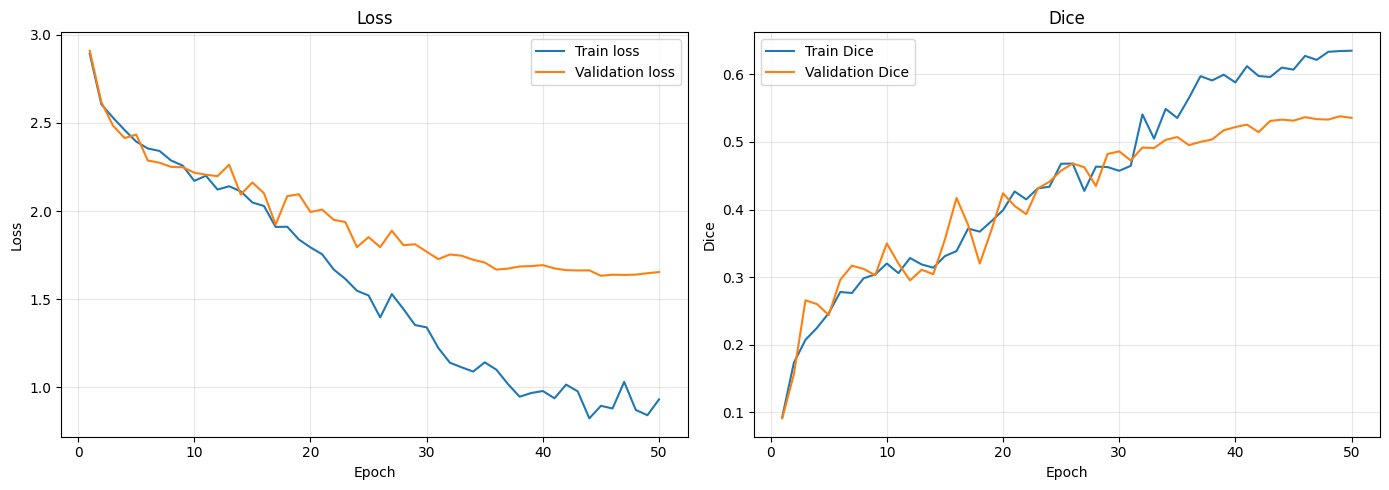

In [32]:
plot_history(history)

### Eval


In [33]:
evaluation_df = evaluate_model(
    model=model,
    loader=test_loader,
    device=device,
    num_classes=CONFIG["num_classes"],
    class_names=CLASS_NAMES,
)

evaluation_df.round(4)

,class_id,class_name,dice,iou,hd95,precision,recall
0,0,background,0.9916,0.9834,6.9799,0.9941,0.9892
1,1,non-neoplastic,0.5644,0.3932,23.6536,0.5117,0.6293
2,2,neoplastic,0.8577,0.7509,14.9729,0.8316,0.8855
3,macro_fg,macro_foreground_only,0.7111,0.5720,19.3132,0.6716,0.7574
4,macro_all,macro_all_classes,0.8046,0.7091,15.2021,0.7791,0.8347
